# 10g — Décodage spéculatif : le draft qui vérifie

Le notebook 10b a construit le KV-cache et relié son coût aux TTFT/ITL réels ; celui-ci traite un autre levier de vitesse que le 10b ne fait que **mentionner** : le **décodage spéculatif**. C'est le sujet du thème 6 de l'EPIC #19543 « ingénierie d'inférence », qui restait hors sujet dans la série.

L'idée tient en une phrase : un petit modèle **propose** une suite de tokens, et le gros modèle les **vérifie tous d'un coup** — ce que l'autorégression ne permettait pas. Ici le mécanisme est entierement from scratch, mesuré sur CPU, sans vLLM : deux vrais modèles n-grammes jouent les rôles de draft (b-gramme) et de cible (4-gramme).

## 1. Le problème : l'autorégression est séquentielle

Générer un texte, c'est produire un token, puis le suivant qui dépend du premier, et ainsi de suite. Chaque token coûte **un passage complet** du modèle cible, et on ne peut pas paralléliser : le token *i+1* n'existe qu'après *i*. Le calcul de la cible est donc le goulot d'étranglement, et la latence de génération (ITL) en est la traduction directe.

Le décodage spéculatif casse cette séquence : au lieu d'attendre un token par passage, on en fait **proposer plusieurs** par un modèle bon marché, puis on les **vérifie en un seul** passage de la cible. Si la cible est d'accord, on a produit plusieurs tokens au prix d'environ un passage.

## 2. Deux vrais modèles n-grammes : le draft et la cible

Pour garder le carnet auto-contenu (CPU, stdlib), le « petit modèle » et le « gros modèle » sont deux vrais modèles probabilistes entraînés from scratch sur le même corpus : un **b-gramme** (contexte d'un mot → rapide, imprécis) et un **4-gramme** (contexte de trois mots → précis, coûteux). Le contenu du corpus n'a pas d'importance pour le mécanisme : il fournit les transitions que les modèles doivent apprendre. Le passage aux vrais LLMs (draft petit / cible 7B) est le même, déclaré `RECOVERABLE-MACHINE` plus bas.

In [1]:
from collections import defaultdict
import random
import math
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (11, 4)
print('imports ok')


imports ok


In [2]:
# Corpus de francais, repetitions locales naturelles : les n-grammes y apprennent des
# transitions stables, ce qui rend le taux d'acceptation net et reproductible.
LIGNES = [
    'la langue est une suite de mots que le modele essaie de prevoir un a la fois',
    'chaque mot depend des mots qui le precedent et le modele apprend ces dependances',
    'un b-gramme regarde le mot precedent et un 4-gramme regarde les trois precedents',
    'plus le contexte est long plus la prediction est precise',
    'mais plus le contexte est long plus il y a peu de phrases qui le partagent',
    'le petit modele est rapide mais imprecis et le gros modele est precis mais lent',
    'le decodage speculatif utilise les deux a la fois',
    'le petit modele propose une suite de mots et le gros modele les verifie',
    'si les mots sont corrects on en garde plusieurs d un coup',
    'si un mot est faux on s arrete et on reprend le bon',
    'le gain depend de la probabilite que le petit modele ait raison',
    'quand le petit modele ressemble au gros on gagne beaucoup',
    'quand il en est loin on perd le temps des verifications',
    'le decodage speculatif ne change pas la qualite des reponses',
    'il ne fait que produire les memes mots plus vite',
    'c est pour ca qu on l utilise dans les serveurs de grands modeles',
    'le texte que le modele lit est une suite de mots tokenises un a un',
    'chaque token est choisi selon la probabilite que le modele lui donne',
    'la probabilite du prochain mot depend du contexte qui le precede',
    'un contexte long donne une probabilite plus sure mais moins de donnees',
    'un contexte court donne moins de surete mais plus de donnees d entrainement',
    'le decodage speculatif est une technique qui accelere la generation',
    'la technique consiste a proposer des mots puis a les verifier',
    'les mots proposes par le petit modele sont appeles le draft',
    'la verification par le gros modele est un seul passage',
    'un seul passage verifie plusieurs mots a la fois',
    'c est pour ca que le decodage est plus rapide',
    'le taux d acceptation mesure la proportion de mots gardes',
    'un taux d acceptation eleve veut dire un grand gain',
    'un taux d acceptation faible veut dire que le draft est mauvais',
    'le choix de la longueur du draft est important',
    'trop court et on gagne peu et trop long et on gaspille',
    'le ratio de cout entre les deux modeles decide du point optimal',
    'le decodage speculatif est un equilibre entre la qualite du draft et son cout',
    'le petit modele propose une suite de mots et le gros modele les verifie',
    'si les mots sont corrects on en garde plusieurs d un coup',
    'le gain depend de la probabilite que le petit modele ait raison',
    'le decodage speculatif est une technique qui accelere la generation',
    'la verification par le gros modele est un seul passage',
    'le taux d acceptation mesure la proportion de mots gardes',
    'le choix de la longueur du draft est important',
    'le ratio de cout entre les deux modeles decide du point optimal',
    'le decodage speculatif est un equilibre entre la qualite du draft et son cout',
]

def tokeniser(texte):
    return [w for w in texte.lower().replace('\n', ' ').split() if w.strip()]

tokens = tokeniser(' '.join(LIGNES))
print('tokens du corpus :', len(tokens))

def build_ngram(tokens, n):
    counts = defaultdict(lambda: defaultdict(int))
    for i in range(max(0, len(tokens) - n)):
        ctx = tuple(tokens[i:i + n - 1])
        counts[ctx][tokens[i + n - 1]] += 1
    totals = {ctx: sum(v.values()) for ctx, v in counts.items()}
    vocab = sorted(set(tokens))
    return {'counts': counts, 'totals': totals, 'vocab': vocab, 'n': n}

draft  = build_ngram(tokens, 2)   # b-gramme  : le 'petit' modele
target = build_ngram(tokens, 4)   # 4-gramme  : le 'gros' modele
print('vocabulaire        :', len(draft['vocab']), 'mots')
print('contextes draft 2g :', len(draft['counts']), '| contextes target 4g :', len(target['counts']))


tokens du corpus : 506
vocabulaire        : 154 mots
contextes draft 2g : 154 | contextes target 4g : 381


## 3. Le mécanisme draft-vérifier (greedy)

La version mesurée est **greedy** (argmax) : à chaque position, le draft propose le mot qu'il juge le plus probable, et la cible vérifie en comparant **son** argmax. On garde le plus long préfixe où les deux sont d'accord, puis on émet le mot de la cible au point de désaccord. C'est l'essentiel du mécanisme, sans le bruit de l'échantillonnage — la version stochastique (test d'acceptance `p_cible > p_draft`, garantie sans perte) a la même dynamique et fait l'objet de l'exercice 1.

In [3]:
def p_args(model, ctx):
    # mot de plus haute probabilite (argmax) selon le modele n-gramme.
    counts = model['counts']; n = model['n']
    cle = tuple(ctx[-(n - 1):]) if n > 1 else ()
    c = counts.get(cle)
    if not c:
        return model['vocab'][0]
    return max(c, key=c.get)

def speculative_greedy(target, draft, prompt, k, max_new):
    # draft-verifier greedy : le draft propose k tokens (argmax), la cible
    # les verifie en UN passage ; on garde le prefixe accepte + 1 token cible.
    ctx = list(prompt)
    n_new = 0; verify_steps = 0; accepted = 0
    while n_new < max_new:
        kk = min(k, max_new - n_new)
        proposed = []; dctx = list(ctx)
        for _ in range(kk):
            w = p_args(draft, dctx)
            proposed.append(w); dctx.append(w)
        verify_steps += 1
        tctx = list(ctx); acc = 0
        for i, w in enumerate(proposed):
            tw = p_args(target, tctx)
            if tw == w:
                tctx.append(tw); acc += 1
            else:
                tctx.append(tw)
                ctx = ctx + proposed[:acc] + [tw]
                n_new += acc + 1; accepted += acc
                break
        else:
            ctx = ctx + proposed
            n_new += kk; accepted += kk
    return n_new, verify_steps, accepted

PROMPT = ['la', 'langue', 'est']
k, max_new = 4, 40
n_new, verify_steps, accepted = speculative_greedy(target, draft, PROMPT, k, max_new)
proposes = verify_steps * k
print('tokens produits         :', n_new)
print('passages cible          :', verify_steps)
print('tokens proposes (draft) :', proposes)
print('acceptes                :', accepted)
print('taux d acceptance a  :', round(accepted / proposes, 3))
print('tokens / passage mu  :', round(n_new / verify_steps, 3))


tokens produits         : 40
passages cible          : 11
tokens proposes (draft) : 44
acceptes                : 38
taux d acceptance a  : 0.864
tokens / passage mu  : 3.636


Une seule invite suffit pour voir le mécanisme : le draft propose 4 tokens par passage, la cible en accepte une partie, et **chaque passage produit plus d'un token** (ici `mu > 1`), là où l'autorégression plain en produirait exactement un. C'est tout le gain, en une ligne.

## 4. Mesurer le taux d'acceptation

On relance la boucle sur une vingtaine d'invites tirées du corpus, pour une gamme de longueurs de draft *k*. Deux grandeurs : le **taux d'acceptation** `a` (fraction de tokens proposés qui sont gardés) et les **tokens par passage** `mu`. On les compare à la borne théorique `1/(1-a)` : si le draft était parfaitement aligné, chaque passage produirait `1/(1-a)` tokens.

In [4]:
prompts = [tokens[i:i + 3] for i in range(0, 42, 3)]

def mesurer(prompts, k, max_new=30):
    tot_new = 0; tot_steps = 0; tot_acc = 0; tot_prop = 0
    for pr in prompts:
        n_new, verify_steps, accepted = speculative_greedy(target, draft, pr, k, max_new)
        tot_new += n_new; tot_steps += verify_steps
        tot_acc += accepted; tot_prop += verify_steps * k
    a = tot_acc / tot_prop
    mu = tot_new / tot_steps
    return a, mu, 1.0 / (1.0 - a)

ks = range(1, 9)
res = {k: mesurer(prompts, k) for k in ks}
print(' k   alpha      mu (tok/passage)   1/(1-a) (borne)')
for k in ks:
    a, mu, borne = res[k]
    print(f'{k}   {a:.3f}      {mu:.3f}                {borne:.3f}')


 k   alpha      mu (tok/passage)   1/(1-a) (borne)
1   0.590      1.000                2.442
2   0.498      1.687                1.992
3   0.374      1.900                1.598
4   0.328      2.222                1.488
5   0.265      2.246                1.361
6   0.222      2.258                1.286
7   0.193      2.283                1.238
8   0.169      2.295                1.204


La lecture est plus subtile qu'elle n'y paraît. Le taux d'acceptation `a` **n'est pas constant** : il décroît de 0,59 (*k*=1) à 0,17 (*k*=8). Plus le draft s'allonge, plus il s'écarte du chemin que la cible aurait suivi — les positions tardives du draft sont acceptées de moins en moins. C'est précisément cette **décroissance** qui fait que `mu` (tokens par passage) croît de façon sous-linéaire puis **sature** vers 2,3 : chaque position de draft ajoutée est acceptée moins souvent, donc rapporte de moins en moins. La colonne `1/(1-a)` est la borne que l'on obtiendrait **si** `a` restait constant à sa moyenne ; on voit qu'elle devient un mauvais guide quand `a` décroît — `mu` la dépasse à *k* grand. C'est le signal qui fixe la longueur de draft optimale.

## 5. Le speedup — et son coût caché

Le gain n'est pas gratuit : chaque passage spéculatif fait **k** calculs de draft (bon marché) **plus** 1 vérification de la cible. On pose le coût d'un passage cible à 1 et le coût d'un token de draft à `r` (ratio). Le speedup face à la cible seule (1 token par passage, coût 1) est alors :

$$\text{speedup} = \frac{\mu}{1 + k \, r}$$

avec `mu` mesuré ci-dessus. Le numérateur est le gain (plus de tokens par passage), le dénominateur le prix (les drafts non acceptés). Le speedup n'est donc **pas monotone** en *k* : il monte, atteint un pic, puis redescend sous 1 quand les drafts coûtent plus qu'ils ne rapportent.

In [5]:
def speedup(mu, k, r):
    return mu / (1.0 + k * r)

rs = [0.05, 0.10, 0.20, 0.30]
print('gain en fonction de k (draft) et r (cout du draft)')
print('  k ' + ''.join(f'|  r={r:.2f}' for r in rs))
print('  ' + '-' * (3 + 9 * len(rs)))
for k in ks:
    a, mu, _ = res[k]
    print(f'{k:3d} ' + ''.join(f'|  {speedup(mu, k, r):.2f}' for r in rs))


gain en fonction de k (draft) et r (cout du draft)
  k |  r=0.05|  r=0.10|  r=0.20|  r=0.30
  ---------------------------------------
  1 |  0.95|  0.91|  0.83|  0.77
  2 |  1.53|  1.41|  1.20|  1.05
  3 |  1.65|  1.46|  1.19|  1.00
  4 |  1.85|  1.59|  1.23|  1.01
  5 |  1.80|  1.50|  1.12|  0.90
  6 |  1.74|  1.41|  1.03|  0.81
  7 |  1.69|  1.34|  0.95|  0.74
  8 |  1.64|  1.28|  0.88|  0.68


Le tableau fait tout le discours. Pour un draft **très bon marché** (`r = 0.05`), le speedup est > 1 dès *k* = 2, culmine à *k* = 4 (1,85) et reste > 1 jusqu'à *k* = 8. Pour un draft **cher** (`r = 0.30`), il ne dépasse 1 que sur une étroite fenêtre *k* = 2-4 et retombe sous 1 dès *k* = 5 — le décodage spéculatif y serait **plus lent** que la cible seule. Le levier décisif n'est pas « aller plus vite » mais **garder le draft à la fois précis et bon marché** : c'est le ratio `r` qui décide si le jeu en vaut la peine.

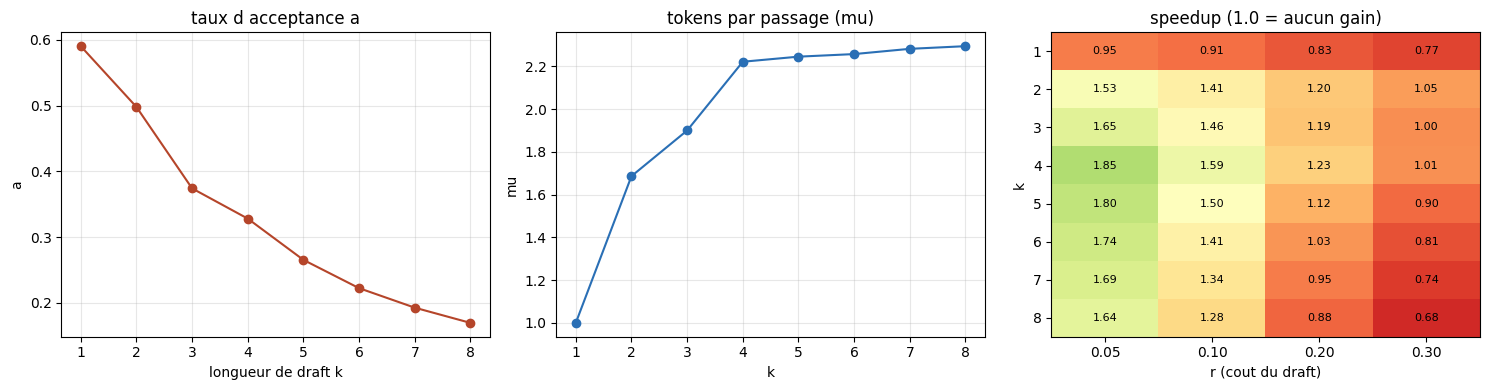

figure produite


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ks_list = list(ks)
alphas = [res[k][0] for k in ks_list]
mus    = [res[k][1] for k in ks_list]

ax[0].plot(ks_list, alphas, 'o-', color='#b5452a')
ax[0].set_title('taux d acceptance a')
ax[0].set_xlabel('longueur de draft k'); ax[0].set_ylabel('a')
ax[0].grid(alpha=0.3)

ax[1].plot(ks_list, mus, 'o-', color='#2a6fb5')
ax[1].set_title('tokens par passage (mu)')
ax[1].set_xlabel('k'); ax[1].set_ylabel('mu')
ax[1].grid(alpha=0.3)

Z = np.array([[speedup(res[k][1], k, r) for r in rs] for k in ks_list])
ax[2].imshow(Z, aspect='auto', cmap='RdYlGn', vmin=0.5, vmax=2.5)
ax[2].set_xticks(range(len(rs))); ax[2].set_xticklabels([f'{r:.2f}' for r in rs])
ax[2].set_yticks(range(len(ks_list))); ax[2].set_yticklabels(ks_list)
ax[2].set_title('speedup (1.0 = aucun gain)')
ax[2].set_xlabel('r (cout du draft)'); ax[2].set_ylabel('k')
for i in range(Z.shape[0]):
    for j in range(Z.shape[1]):
        ax[2].text(j, i, f'{Z[i,j]:.2f}', ha='center', va='center', fontsize=8)
plt.tight_layout()
plt.show()
print('figure produite')

La figure résume le carnet. À gauche, `a` **décroît** avec *k* — le draft prédit bien le mot suivant, de moins en moins bien les suivants : c'est la mesure qui prédit tout. Au centre, `mu` monte puis **sature** vers 2,3, à cause de cette décroissance. À droite, la carte speedup : la zone verte (gain) s'étend vers les *k* grands **quand r est petit**, et se referme vers la zone rouge (perte) dès que le draft coûte cher. C'est exactement le compromis que les systèmes d'inférence réels arbitrent en choisissant le modèle draft.

## 6. Ce que le carnet ne mesure pas

Le mécanisme est **identique** pour de vrais LLMs : le draft y est un petit modèle, la cible un 7B, et le passage de vérification exploite le parallélisme des *k* positions. Ici, draft et cible sont des n-grammes réels entraînés sur CPU — c'est ce qui rend le carnet auto-contenu et les taux d'acceptation **nets** (pas noyés sous la latence réseau d'un endpoint). La mesure du speedup **réel** (2-3×) sur un endpoint de service vLLM authentiﬁé est `RECOVERABLE-MACHINE` : elle demande la machine GPU qui sert vLLM, pas une réécriture du mécanisme.

Deux limites à garder en tête : (1) le speedup mesuré est un **rapport de coût** modélisé (`mu / (1+k r)`), pas un chronomètre — la forme de la courbe et son point de bascule sont robustes, l'ampleur exacte dépend du ratio `r` réel ; (2) l'acceptation greedy ignore le déplacement de distribution que la version stochastique gère (exercice 1).

## 7. Exercices

Trois passes pour aller au-delà de la version greedy mesurée : la version stochastique sans perte, la recherche de la longueur de draft optimale, et le passage au draft en arbre.

In [7]:
def speculative_sampling(target, draft, prompt, k, max_new, seed=42):
    # Etape 1 : echantillonner chaque token du draft selon sa distribution.
    # Etape 2 : accepter le token i si p_cible(x) > p_draft(x), sinon
    #           re-echantillonner depuis max(0, p_cible - p_draft) et arreter.
    # Etape 3 : verifier que la distribution de sortie est identique a la cible
    #           seule (c'est la garantie 'sans perte' du decodage speculatif).
    return None  # TODO etudiant


**Exercice 1 — la version stochastique sans perte.** La version mesurée est greedy. Réécrivez `speculative_sampling` avec l'échantillonnage et le test d'acceptance : c'est elle qui garantit que la distribution de sortie est **exactement** celle de la cible seule, contrairement au greedy qui peut la décalée. Montrez la garantie sur un prompt de test.

In [8]:
def k_optimal(prompts, r=0.10, k_max=12, max_new=30):
    # Balayez k de 1 a k_max, calculez speedup(mu, k, r) pour chaque k,
    # et renvoyez (k_optimal, speedup_max). Le maximum n'est pas en k_max :
    # au-dela d'un point, les drafts non accepts coutent plus qu'ils ne rapportent.
    return None  # TODO etudiant


**Exercice 2 — la longueur de draft optimale.** Le speedup `mu / (1 + k r)` n'est pas monotone en *k*. Balayez *k* pour `r = 0.10` et trouvez le *k* qui le maximise. C'est le choix concret qu'un système d'inférence doit faire : trop court gaspille le parallélisme, trop long gaspille les drafts.

In [9]:
def speculative_tree(target, draft, prompt, k, b, max_new):
    # A chaque position, le draft propose b candidats (branching) ; la cible
    # verifie l'ARBRE des prefixs acceptes en un passage. Renvoyez
    # (tokens_par_passage, alpha) et comparez au draft lineaire de la section 4.
    return None  # TODO etudiant


**Exercice 3 — le draft en arbre.** Le draft linéaire propose une seule suite ; un draft **en arbre** propose *b* candidats par position et la cible vérifie tout l'arbre d'un coup. Mesurez le gain en tokens par passage face au linéaire, pour `b = 2` et `b = 3` : c'est la version que les serveurs réels déploient pour pousser le taux d'acceptation plus haut.

## En résumé

Le décodage spéculatif transforme la séquence stricte de l'autorégression en « proposer puis vérifier » : un petit modèle avance, le gros modèle confirme, et chaque passage cible produit plusieurs tokens. Le gain se réduit à deux nombres mesurés ici — le taux d'acceptation `a` (qualité du draft) et le ratio de coût `r` (prix du draft) — et son point de bascule, là où le speedup repasse sous 1. C'est le même arbitrage que font les systèmes d'inférence en production, posé ici en from scratch et mesuré sur CPU.